# Foundations of the Tree Data Structure
**Hamed Tabrizchi, PhD** · Data Structures and Algorithms

Companion notebook to the lecture slides. Every example from the slides is implemented here **from scratch, in an object-oriented way** (no external tree libraries; `matplotlib` is used only to draw figures).

| Part | Content |
|---|---|
| 1 | General tree: node class, tree class and the tree ADT (`CREATE`, `ISEMPTY`, `ROOT`, `PARENT`, `LEFTMOSTCHILD`, `RIGHTSIBLING`, `SIZE`) |
| 2 | Terminology and measures (depth, height, degree, level, ancestors, ...) |
| 3 | Binary tree class and the three traversals: preorder, inorder, postorder |
| 4 | Equivalent binary tree (left-child, right-sibling) and the traversal correspondence |
| 5 | Applications from the slides: expression tree, directory size, binary search tree |
| 6 | Complexity experiment and exercises |

## Part 1 · General tree and the tree ADT

**Representation (slide "Representation").** Each node stores four fields: `element`, `parent`, `first_child` (leftmost child) and `next_sibling` (right sibling). A node therefore has a fixed size no matter how many children it has, and the whole structure uses O(n) space.

In [1]:
from collections import deque


class TreeNode:
    """Node of a general (ordered) tree: first-child / next-sibling representation."""

    __slots__ = ("element", "parent", "first_child", "next_sibling")

    def __init__(self, element, parent=None):
        self.element = element
        self.parent = parent
        self.first_child = None     # leftmost child
        self.next_sibling = None    # right sibling

    def is_leaf(self):
        return self.first_child is None

    def children(self):
        """Yield the children from left to right using only the two child links."""
        c = self.first_child
        while c is not None:
            yield c
            c = c.next_sibling

    def __repr__(self):
        return f"TreeNode({self.element!r})"

**The `Tree` class.** The seven ADT operations from the slides are implemented as methods with the same names (in `snake_case`). Building methods (`add_root`, `add_child`) are added so that trees can be created in code.

In [2]:
class Tree:
    """General tree ADT with the operations CREATE, ISEMPTY, ROOT, PARENT,
    LEFTMOSTCHILD, RIGHTSIBLING and SIZE."""

    # ------------------------------------------------------------ ADT operations
    def __init__(self):                     # CREATE()  -- O(1)
        self._root = None
        self._size = 0

    def is_empty(self):                     # ISEMPTY(T)  -- O(1)
        return self._root is None

    def root(self):                         # ROOT(T)  -- O(1)
        if self.is_empty():
            raise ValueError("empty tree")
        return self._root

    def parent(self, v):                    # PARENT(T, v)  -- O(1)
        if v is self._root:
            return None
        return v.parent

    def leftmost_child(self, v):            # LEFTMOSTCHILD(v)  -- O(1)
        return v.first_child

    def right_sibling(self, v):             # RIGHTSIBLING(v)  -- O(1)
        return v.next_sibling

    def size(self):                         # SIZE(T)  -- O(1) with a maintained counter
        return self._size

    def count(self, v=None):                # COUNT(v)  -- O(n): size by traversal
        """Recursive size of the subtree rooted at v (pseudocode of the slides)."""
        if v is None:
            if self.is_empty():
                return 0
            v = self._root
        n = 1
        c = self.leftmost_child(v)
        while c is not None:
            n += self.count(c)
            c = self.right_sibling(c)
        return n

    # ------------------------------------------------------------ construction
    def add_root(self, element):
        if not self.is_empty():
            raise ValueError("tree already has a root")
        self._root = TreeNode(element)
        self._size = 1
        return self._root

    def add_child(self, p, element):
        """Append a new rightmost child below p."""
        node = TreeNode(element, parent=p)
        if p.first_child is None:
            p.first_child = node
        else:
            last = p.first_child
            while last.next_sibling is not None:
                last = last.next_sibling
            last.next_sibling = node
        self._size += 1
        return node

    @classmethod
    def from_nested(cls, spec):
        """Build a tree from nested tuples: ("A", [("B", [...]), ("C", [])])."""
        t = cls()

        def build(parent, s):
            element, kids = s
            node = t.add_root(element) if parent is None else t.add_child(parent, element)
            for k in kids:
                build(node, k)

        build(None, spec)
        return t

    def find(self, element):
        for v in self.preorder():
            if v.element == element:
                return v
        raise KeyError(element)

    def __getitem__(self, element):         # T["B"] -> node
        return self.find(element)

    def __len__(self):
        return self._size

### Traversals, measures and terminology on the general tree
These methods extend `Tree` (they are attached with a small helper so the notebook stays readable cell by cell). They implement the vocabulary from the slides: root, parent, child, siblings, leaf, internal node, ancestors, descendants, edge, degree, depth, level, height and size.

In [3]:
def extend(cls):
    """Decorator that adds the decorated function as a method of `cls`."""
    def deco(fn):
        setattr(cls, fn.__name__, fn)
        return fn
    return deco


# ---- traversals of a general tree (generators; v defaults to the root)
@extend(Tree)
def preorder(self, v=None):
    if v is None:
        if self.is_empty():
            return
        v = self._root
    yield v
    for c in v.children():
        yield from self.preorder(c)

@extend(Tree)
def postorder(self, v=None):
    if v is None:
        if self.is_empty():
            return
        v = self._root
    for c in v.children():
        yield from self.postorder(c)
    yield v

@extend(Tree)
def level_order(self):
    if self.is_empty():
        return
    q = deque([self._root])
    while q:
        v = q.popleft()
        yield v
        q.extend(v.children())


# ---- terminology
@extend(Tree)
def siblings(self, v):
    return [] if v.parent is None else [c for c in v.parent.children() if c is not v]

@extend(Tree)
def ancestors(self, v):
    out, p = [], v.parent
    while p is not None:
        out.append(p)
        p = p.parent
    return out

@extend(Tree)
def descendants(self, v):
    return list(self.preorder(v))[1:]

@extend(Tree)
def leaves(self):
    return [v for v in self.preorder() if v.is_leaf()]

@extend(Tree)
def internal_nodes(self):
    return [v for v in self.preorder() if not v.is_leaf()]

@extend(Tree)
def edges(self):
    return [(v.parent.element, v.element) for v in self.preorder() if v.parent is not None]


# ---- measures
@extend(Tree)
def degree(self, v):
    return sum(1 for _ in v.children())

@extend(Tree)
def tree_degree(self):
    return max(self.degree(v) for v in self.preorder())

@extend(Tree)
def depth(self, v):
    return len(self.ancestors(v))

@extend(Tree)
def level(self, k):
    return [v for v in self.preorder() if self.depth(v) == k]

@extend(Tree)
def height(self, v=None):
    """Number of edges on the longest downward path from v (default: root)."""
    if v is None:
        v = self._root
    return 0 if v.is_leaf() else 1 + max(self.height(c) for c in v.children())


# ---- text display
@extend(Tree)
def pretty(self):
    lines = [str(self._root.element)]
    def walk(v, prefix):
        kids = list(v.children())
        for i, c in enumerate(kids):
            last = i == len(kids) - 1
            lines.append(prefix + ("└── " if last else "├── ") + str(c.element))
            walk(c, prefix + ("    " if last else "│   "))
    walk(self._root, "")
    return "\n".join(lines)

print("Tree class ready, methods:", [m for m in dir(Tree) if not m.startswith("_")])

Tree class ready, methods: ['add_child', 'add_root', 'ancestors', 'count', 'degree', 'depth', 'descendants', 'edges', 'find', 'from_nested', 'height', 'internal_nodes', 'is_empty', 'leaves', 'leftmost_child', 'level', 'level_order', 'parent', 'postorder', 'preorder', 'pretty', 'right_sibling', 'root', 'siblings', 'size', 'tree_degree']


### Figures
A tiny drawing helper (matplotlib only) that reproduces the figures of the slides: **maroon** root, **navy** internal nodes, outlined leaves. Optional numbered badges show visiting order.

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

NAVY, MAROON, GOLD, GOLDD = "#12263f", "#8a1c2b", "#b5893a", "#8a6a22"


def _draw(pos, edges, style, title=None, badges=None, edge_style=None, figsize=(7, 4.2)):
    fig, ax = plt.subplots(figsize=figsize)
    for a, b in edges:
        color, ls = edge_style(a, b) if edge_style else (NAVY, "-")
        ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]], color=color, ls=ls, lw=2, zorder=1)
    for k, (x, y) in pos.items():
        face, text, edge = style(k)
        ax.add_patch(Circle((x, y), 0.32, facecolor=face, edgecolor=edge, lw=2, zorder=2))
        ax.text(x, y, str(k), ha="center", va="center", color=text, fontsize=14, fontweight="bold", zorder=3)
        if badges and k in badges:
            ax.add_patch(Circle((x + 0.28, y + 0.30), 0.17, facecolor="white", edgecolor=GOLD, lw=2, zorder=4))
            ax.text(x + 0.28, y + 0.30, str(badges[k]), ha="center", va="center", fontsize=9, fontweight="bold", color=NAVY, zorder=5)
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.8, max(xs) + 0.8); ax.set_ylim(min(ys) - 0.8, max(ys) + 0.8)
    ax.set_aspect("equal"); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=13, color=NAVY)
    plt.show()


def draw_tree(T, title=None, badges=None):
    """Draw a general Tree: leaves get consecutive x slots, parents sit above their children."""
    pos, nxt = {}, [0.0]
    def place(v):
        kids = list(v.children())
        if not kids:
            x = nxt[0]; nxt[0] += 1.0
        else:
            xs = [place(c) for c in kids]
            x = (xs[0] + xs[-1]) / 2
        pos[v.element] = (x, -T.depth(v))
        return x
    place(T.root())
    def style(k):
        v = T[k]
        if v is T.root():
            return MAROON, "white", MAROON
        return (NAVY, "white", NAVY) if not v.is_leaf() else ("white", NAVY, NAVY)
    _draw(pos, T.edges(), style, title, badges)

### Running example (slides "Terminology" and "Applying the Operations")
The example tree has 8 nodes: `A` has children `B, C, D`; `B` has `E, F`; `D` has `G`; `F` has `H`.

A
├── B
│   ├── E
│   └── F
│       └── H
├── C
└── D
    └── G



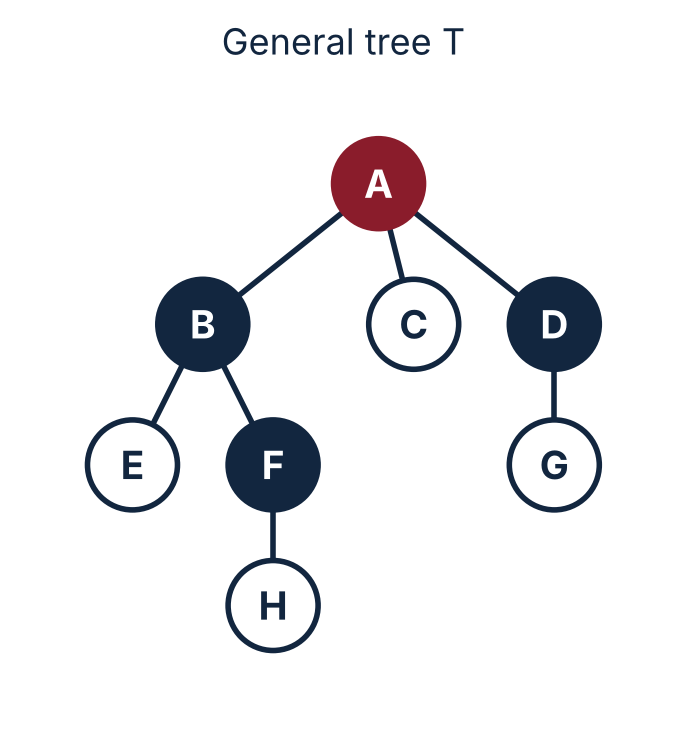

In [5]:
T = Tree.from_nested(
    ("A", [("B", [("E", []), ("F", [("H", [])])]),
           ("C", []),
           ("D", [("G", [])])])
)
print(T.pretty())
print()
draw_tree(T, "General tree T")

### Applying the operations (slide "Applying the Operations")
The table below is computed with the ADT methods; it reproduces the slide, including the `NIL` results (`None` in Python).

In [6]:
def show(x):
    return "NIL" if x is None else (x.element if isinstance(x, TreeNode) else x)

calls = [
    ("ROOT(T)",             lambda: T.root()),
    ("PARENT(T, H)",        lambda: T.parent(T["H"])),
    ("PARENT(T, A)",        lambda: T.parent(T["A"])),
    ("LEFTMOSTCHILD(B)",    lambda: T.leftmost_child(T["B"])),
    ("LEFTMOSTCHILD(C)",    lambda: T.leftmost_child(T["C"])),
    ("RIGHTSIBLING(E)",     lambda: T.right_sibling(T["E"])),
    ("RIGHTSIBLING(D)",     lambda: T.right_sibling(T["D"])),
    ("SIZE(T)",             lambda: T.size()),
    ("ISEMPTY(T)",          lambda: T.is_empty()),
]
print(f"{'Call':<22}Result")
print("-" * 30)
for name, f in calls:
    print(f"{name:<22}{show(f())}")

# CREATE(): a brand-new tree is empty
E = Tree()
print("\nCREATE() ->  ISEMPTY:", E.is_empty(), "| SIZE:", E.size())
try:
    E.root()
except ValueError as err:
    print("ROOT(empty tree) raises ValueError:", err)

# Enumerate the children of B with the two child operations only
c, kids = T.leftmost_child(T["B"]), []
while c is not None:
    kids.append(c.element)
    c = T.right_sibling(c)
print("Children of B via LEFTMOSTCHILD / RIGHTSIBLING:", kids)

# SIZE two ways
print("size() counter =", T.size(), "| count() by traversal =", T.count())
assert T.size() == T.count() == 8

Call                  Result
------------------------------
ROOT(T)               A
PARENT(T, H)          F
PARENT(T, A)          NIL
LEFTMOSTCHILD(B)      E
LEFTMOSTCHILD(C)      NIL
RIGHTSIBLING(E)       F
RIGHTSIBLING(D)       NIL
SIZE(T)               8
ISEMPTY(T)            False

CREATE() ->  ISEMPTY: True | SIZE: 0
ROOT(empty tree) raises ValueError: empty tree
Children of B via LEFTMOSTCHILD / RIGHTSIBLING: ['E', 'F']
size() counter = 8 | count() by traversal = 8


## Part 2 · Terminology and measures
Everything in the slides "Terminology", "Measures of a Tree" and "Principles of a Tree". Root has depth 0 and a single-node tree has height 0.

In [7]:
names = lambda nodes: [v.element for v in nodes]

print("Root               :", T.root().element)
print("Parent of E        :", T.parent(T["E"]).element)
print("Children of A      :", names(T["A"].children()))
print("Siblings of B      :", names(T.siblings(T["B"])))
print("Leaves             :", names(T.leaves()))
print("Internal nodes     :", names(T.internal_nodes()))
print("Ancestors of H     :", names(T.ancestors(T["H"])))
print("Descendants of B   :", names(T.descendants(T["B"])))
print("Edges              :", T.edges())
print()
print("degree(A), degree(B) :", T.degree(T["A"]), T.degree(T["B"]))
print("degree of the tree   :", T.tree_degree())
print("depth(H)             :", T.depth(T["H"]))
print("level 2              :", names(T.level(2)))
print("height(B)            :", T.height(T["B"]))
print("height(T)            :", T.height())
print("size |T|             :", T.size())

# Principle checks from the slides
assert T.size() - 1 == len(T.edges())                      # n nodes -> n-1 edges
assert all((v is T.root()) == (v.parent is None) for v in T.preorder())  # exactly one root, others have a parent
assert names(T.ancestors(T["H"])) == ["F", "B", "A"]
assert names(T.leaves()) == ["E", "H", "C", "G"]
assert names(T.level(2)) == ["E", "F", "G"]
assert (T.depth(T["H"]), T.height(T["B"]), T.height()) == (3, 2, 3)
print("\nAll terminology checks passed.")

Root               : A
Parent of E        : B
Children of A      : ['B', 'C', 'D']
Siblings of B      : ['C', 'D']
Leaves             : ['E', 'H', 'C', 'G']
Internal nodes     : ['A', 'B', 'F', 'D']
Ancestors of H     : ['F', 'B', 'A']
Descendants of B   : ['E', 'F', 'H']
Edges              : [('A', 'B'), ('B', 'E'), ('B', 'F'), ('F', 'H'), ('A', 'C'), ('A', 'D'), ('D', 'G')]

degree(A), degree(B) : 3 2
degree of the tree   : 3
depth(H)             : 3
level 2              : ['E', 'F', 'G']
height(B)            : 2
height(T)            : 3
size |T|             : 8

All terminology checks passed.


In [8]:
# Traversals of the general tree T (needed later for the equivalence with the binary tree)
print("Preorder  of T:", " ".join(names(T.preorder())))
print("Postorder of T:", " ".join(names(T.postorder())))
print("Level-order  T:", " ".join(names(T.level_order())))

Preorder  of T: A B E F H C D G
Postorder of T: E H F B C G D A
Level-order  T: A B C D E F G H


## Part 3 · Binary tree and the three traversals

A **binary tree** gives every node at most two ordered children: `left` and `right`. Traversal rules (N = node, L = left subtree, R = right subtree):

| Order | Rule | Typical use |
|---|---|---|
| Preorder | N → L → R | copy a tree, prefix expressions |
| Inorder | L → N → R | sorted output from a binary search tree |
| Postorder | L → R → N | delete a tree, postfix expressions |

In [9]:
class BinaryNode:
    __slots__ = ("element", "left", "right")

    def __init__(self, element, left=None, right=None):
        self.element = element
        self.left = left
        self.right = right

    def __repr__(self):
        return f"BinaryNode({self.element!r})"


class BinaryTree:
    def __init__(self, root=None):
        self.root = root

    # --------------------------------------------------------- construction
    @classmethod
    def from_nested(cls, spec):
        """spec = (element, left_spec_or_None, right_spec_or_None)"""
        def build(s):
            if s is None:
                return None
            e, l, r = s
            return BinaryNode(e, build(l), build(r))
        return cls(build(spec))

    # --------------------------------------------------------- recursive traversals (slides)
    def preorder(self, v="root"):
        v = self.root if v == "root" else v
        if v is None:                      # if v = NIL then return
            return
        yield v                            # visit(v)
        yield from self.preorder(v.left)
        yield from self.preorder(v.right)

    def inorder(self, v="root"):
        v = self.root if v == "root" else v
        if v is None:
            return
        yield from self.inorder(v.left)
        yield v                            # visit(v) between the subtrees
        yield from self.inorder(v.right)

    def postorder(self, v="root"):
        v = self.root if v == "root" else v
        if v is None:
            return
        yield from self.postorder(v.left)
        yield from self.postorder(v.right)
        yield v                            # visit(v) after the subtrees

    # --------------------------------------------------------- iterative versions (explicit stack, no recursion limit)
    def preorder_iter(self):
        stack, v = ([self.root] if self.root else []), None
        while stack:
            v = stack.pop()
            yield v
            if v.right: stack.append(v.right)
            if v.left:  stack.append(v.left)

    def inorder_iter(self):
        stack, v = [], self.root
        while stack or v:
            while v:
                stack.append(v); v = v.left
            v = stack.pop()
            yield v
            v = v.right

    def postorder_iter(self):
        stack, last, v = [], None, self.root
        while stack or v:
            if v:
                stack.append(v); v = v.left
            else:
                top = stack[-1]
                if top.right and last is not top.right:
                    v = top.right
                else:
                    yield top
                    last = stack.pop()

    def level_order(self):
        q = deque([self.root] if self.root else [])
        while q:
            v = q.popleft()
            yield v
            if v.left:  q.append(v.left)
            if v.right: q.append(v.right)

    # --------------------------------------------------------- measures
    def size(self, v="root"):
        v = self.root if v == "root" else v
        return 0 if v is None else 1 + self.size(v.left) + self.size(v.right)

    def height(self, v="root"):
        """Edges on the longest downward path; the empty tree has height -1."""
        v = self.root if v == "root" else v
        return -1 if v is None else 1 + max(self.height(v.left), self.height(v.right))

    def height_iter(self):
        """Height by counting breadth-first levels (no recursion)."""
        h, level = -1, deque([self.root] if self.root else [])
        while level:
            h += 1
            for _ in range(len(level)):
                v = level.popleft()
                if v.left:  level.append(v.left)
                if v.right: level.append(v.right)
        return h

    def leaves(self):
        return [v for v in self.preorder() if v.left is None and v.right is None]

    def edges(self):
        out = []
        for v in self.preorder():
            if v.left:  out.append((v.element, v.left.element, "L"))
            if v.right: out.append((v.element, v.right.element, "R"))
        return out

    def depth_of(self):
        d, q = {}, deque([(self.root, 0)] if self.root else [])
        while q:
            v, k = q.popleft(); d[v.element] = k
            if v.left:  q.append((v.left, k + 1))
            if v.right: q.append((v.right, k + 1))
        return d

    def draw(self, title=None, order=None):
        """Draw with x = inorder rank and y = -depth (the layout used in the slides)."""
        depth = self.depth_of()
        pos = {v.element: (i, -depth[v.element]) for i, v in enumerate(self.inorder())}
        left_set = {v.element for v in self.inorder(self.root.left)}
        def style(k):
            if k == self.root.element: return MAROON, "white", MAROON
            return (NAVY, "white", NAVY) if k in left_set else (GOLDD, "white", GOLDD)
        badges = {k: i + 1 for i, k in enumerate(order)} if order else None
        _draw(pos, [(a, b) for a, b, _ in self.edges()], style, title, badges, figsize=(9, 4.4))

### Running example for the traversals (slides "Binary Trees", "Preorder", "Inorder", "Postorder")
`A` has children `B, C`; `B` has `D, E`; `E` has left child `G`; `C` has only a right child `F`; `F` has left child `H`.

In [10]:
B = BinaryTree.from_nested(
    ("A",
        ("B", ("D", None, None),
              ("E", ("G", None, None), None)),
        ("C", None,
              ("F", ("H", None, None), None)))
)
seq = lambda it: [v.element for v in it]

pre, ino, post = seq(B.preorder()), seq(B.inorder()), seq(B.postorder())
print("Preorder  (N L R):", " ".join(pre))
print("Inorder   (L N R):", " ".join(ino))
print("Postorder (L R N):", " ".join(post))
print("Level-order      :", " ".join(seq(B.level_order())))

# Values shown in the slides
assert pre  == list("ABDEGCFH")
assert ino  == list("DBGEACHF")
assert post == list("DGEBHFCA")

# Recursive and iterative implementations agree
assert seq(B.preorder_iter())  == pre
assert seq(B.inorder_iter())   == ino
assert seq(B.postorder_iter()) == post
print("\nSlide sequences reproduced; recursive == iterative.")

Preorder  (N L R): A B D E G C F H
Inorder   (L N R): D B G E A C H F
Postorder (L R N): D G E B H F C A
Level-order      : A B C D E F G H

Slide sequences reproduced; recursive == iterative.


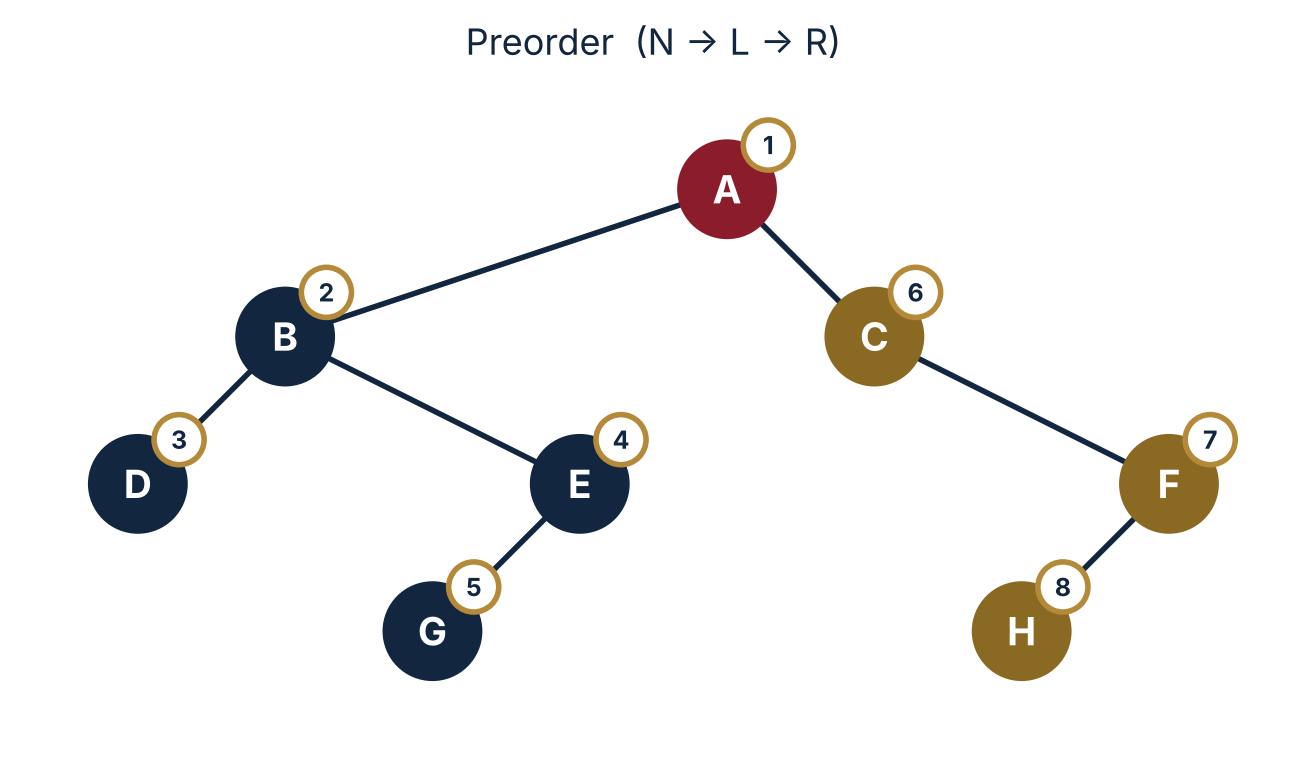

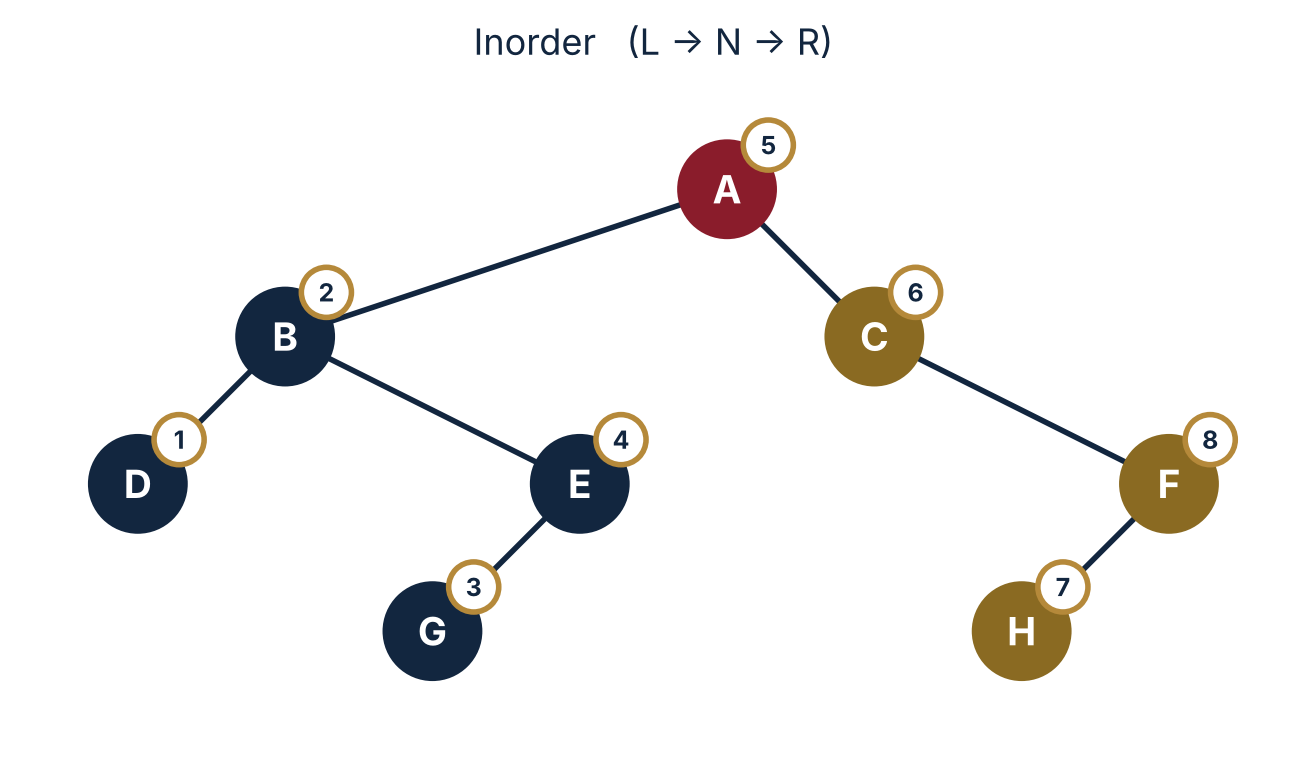

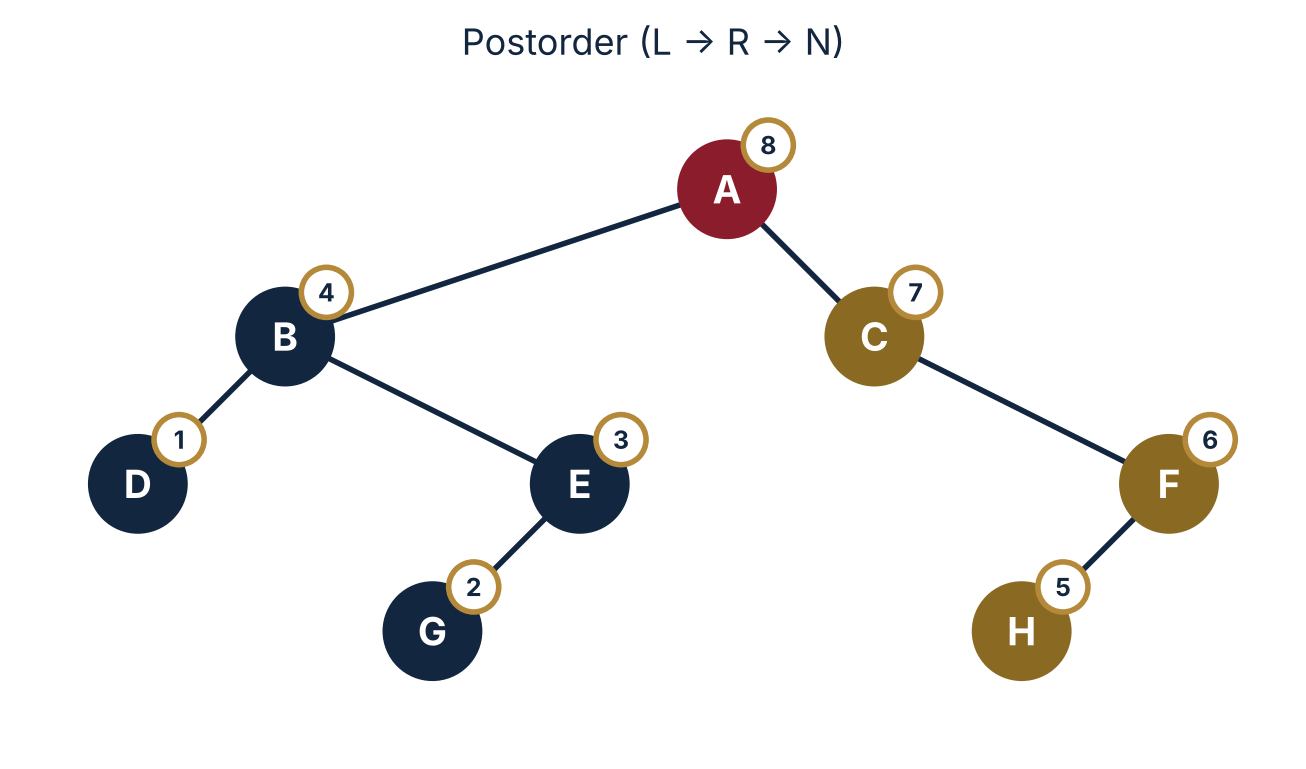

In [11]:
B.draw("Preorder  (N → L → R)", order=pre)
B.draw("Inorder   (L → N → R)", order=ino)
B.draw("Postorder (L → R → N)", order=post)

### Following the recursion (trace)
A call trace makes the three rules visible: the only difference is *where* `visit` happens.

In [12]:
def trace(node, order, depth=0):
    """Print every call; 'visit' lines are the output of the traversal."""
    pad = "  " * depth
    if node is None:
        print(f"{pad}{order.upper()}(NIL) -> return")
        return
    print(f"{pad}{order.upper()}({node.element})")
    if order == "pre":
        print(f"{pad}  visit {node.element}")
    trace(node.left, order, depth + 1)
    if order == "in":
        print(f"{pad}  visit {node.element}")
    trace(node.right, order, depth + 1)
    if order == "post":
        print(f"{pad}  visit {node.element}")

# small subtree (B with D, E, G) to keep the trace short
sub = BinaryTree(B.root.left)
trace(sub.root, "in")

IN(B)
  IN(D)
    IN(NIL) -> return
    visit D
    IN(NIL) -> return
  visit B
  IN(E)
    IN(G)
      IN(NIL) -> return
      visit G
      IN(NIL) -> return
    visit E
    IN(NIL) -> return


### Binary tree properties (slide "Binary Trees")
Level *i* holds at most 2^i nodes, height *h* allows at most 2^(h+1) − 1 nodes, and leaves = (nodes with two children) + 1.

In [13]:
by_level = {}
for el, d in B.depth_of().items():
    by_level.setdefault(d, []).append(el)

for i, nodes in sorted(by_level.items()):
    print(f"level {i}: {nodes!s:<22} count={len(nodes)}  max=2^{i}={2**i}")
    assert len(nodes) <= 2 ** i

h, n = B.height(), B.size()
print(f"\nheight h = {h}, n = {n}, max nodes = 2^(h+1)-1 = {2**(h+1)-1}")
assert n <= 2 ** (h + 1) - 1

n2 = sum(1 for v in B.preorder() if v.left and v.right)
n0 = len(B.leaves())
print(f"leaves n0 = {n0}, nodes with two children n2 = {n2}  ->  n0 = n2 + 1: {n0 == n2 + 1}")
assert n0 == n2 + 1

level 0: ['A']                  count=1  max=2^0=1
level 1: ['B', 'C']             count=2  max=2^1=2
level 2: ['D', 'E', 'F']        count=3  max=2^2=4
level 3: ['G', 'H']             count=2  max=2^3=8

height h = 3, n = 8, max nodes = 2^(h+1)-1 = 15
leaves n0 = 3, nodes with two children n2 = 2  ->  n0 = n2 + 1: True


## Part 4 · Equivalent binary tree (left-child, right-sibling)

For every node `v` of an ordered tree T:

* `left(v)`  = leftmost child of `v`  (`LEFTMOSTCHILD`)
* `right(v)` = right sibling of `v`   (`RIGHTSIBLING`)

The classmethod `BinaryTree.from_tree` below applies exactly the three steps from the slides: connect siblings, prune all but the leftmost-child edge, then read the two links as left and right pointers. `to_tree` reverses the transformation, which shows the mapping is one-to-one.

In [14]:
def _from_tree(cls, T):
    """B(T): left = leftmost child, right = right sibling."""
    def convert(v):
        if v is None:
            return None
        return BinaryNode(v.element,
                          left=convert(T.leftmost_child(v)),
                          right=convert(T.right_sibling(v)))
    return cls(convert(T.root()) if not T.is_empty() else None)

def _to_tree(self):
    """Inverse transformation: rebuild the general tree from B(T)."""
    if self.root is None:
        return Tree()
    if self.root.right is not None:
        raise ValueError("root of B(T) cannot have a right sibling (it would be a forest)")
    T = Tree()
    r = T.add_root(self.root.element)

    def attach(parent, b):
        while b is not None:                 # walk the sibling chain (right links)
            n = T.add_child(parent, b.element)
            attach(n, b.left)                # children of b (left link)
            b = b.right
    attach(r, self.root.left)
    return T

BinaryTree.from_tree = classmethod(_from_tree)
BinaryTree.to_tree = _to_tree

BT = BinaryTree.from_tree(T)
for a, b, kind in BT.edges():
    print(f"{a} -> {b}   ({'left = first child' if kind == 'L' else 'right = next sibling'})")

A -> B   (left = first child)
B -> E   (left = first child)
B -> C   (right = next sibling)
E -> F   (right = next sibling)
F -> H   (left = first child)
C -> D   (right = next sibling)
D -> G   (left = first child)


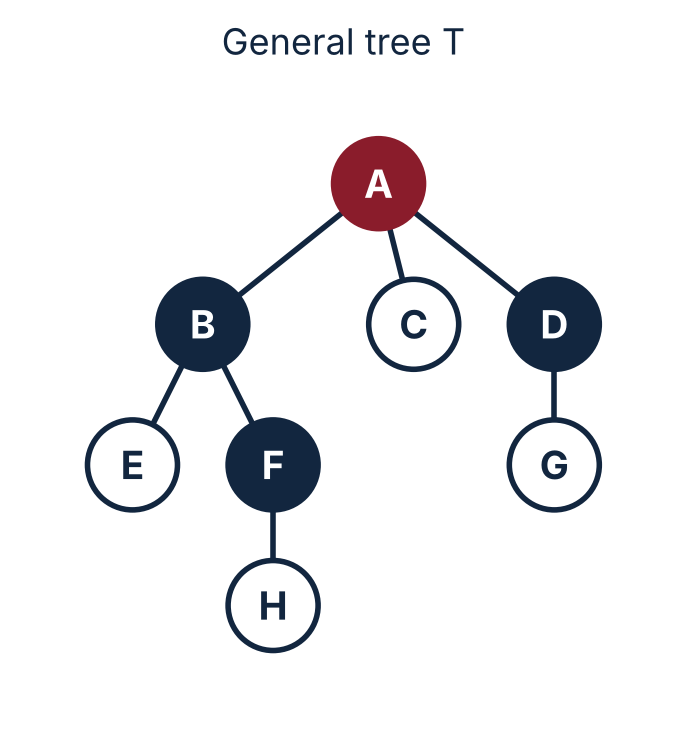

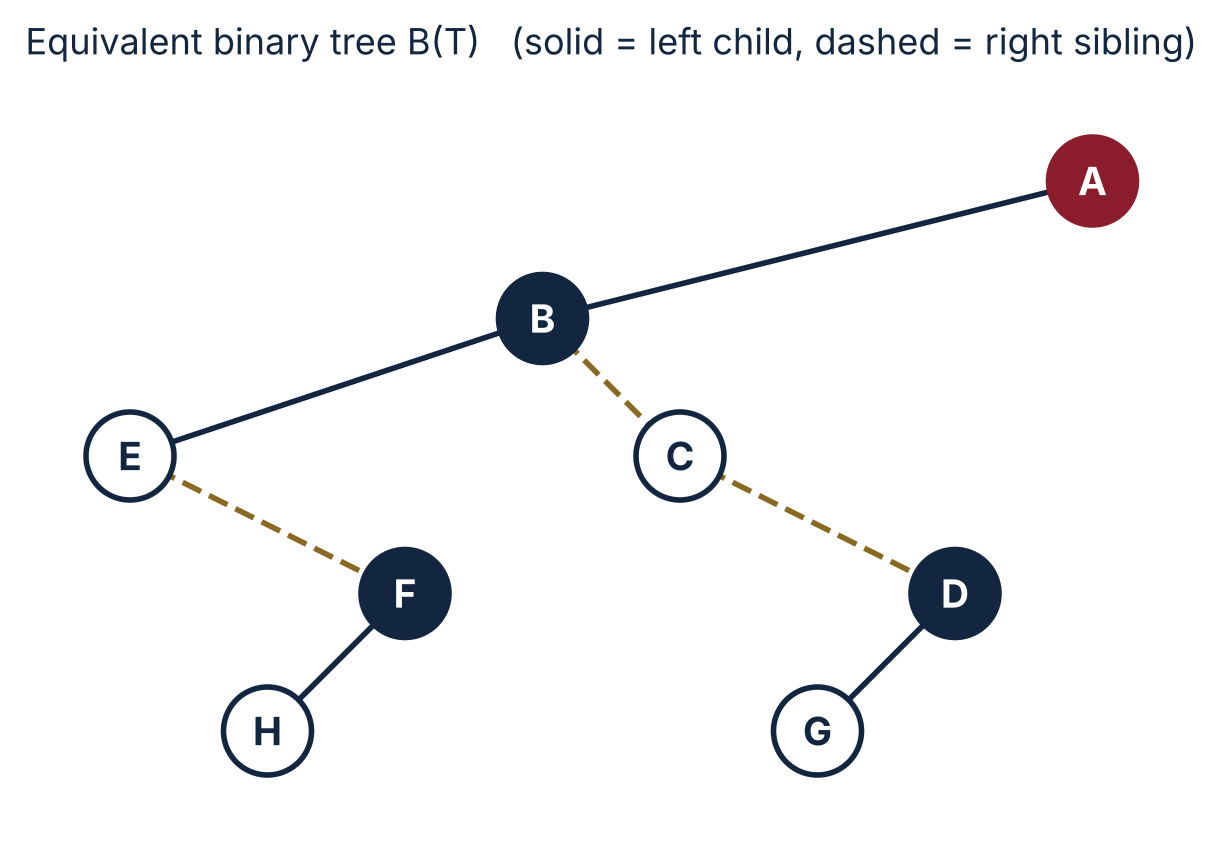

In [15]:
# Figure of the slide: general tree T and its equivalent binary tree B(T)
draw_tree(T, "General tree T")

depth = BT.depth_of()
pos = {v.element: (i, -depth[v.element]) for i, v in enumerate(BT.inorder())}
def gstyle(k):
    v = T[k]
    if v is T.root(): return MAROON, "white", MAROON
    return (NAVY, "white", NAVY) if not v.is_leaf() else ("white", NAVY, NAVY)
_draw(pos, [(a, b) for a, b, _ in BT.edges()], gstyle, "Equivalent binary tree B(T)   (solid = left child, dashed = right sibling)",
      edge_style=lambda a, b: ((GOLDD, "--") if any(x == a and y == b and k == "R" for x, y, k in BT.edges()) else (NAVY, "-")),
      figsize=(10, 5))

In [16]:
# Traversal correspondence (slide "Traversals of T and B(T)")
print("Preorder  of T   :", " ".join(names(T.preorder())))
print("Preorder  of B(T):", " ".join(seq(BT.preorder())))
print("Postorder of T   :", " ".join(names(T.postorder())))
print("Inorder   of B(T):", " ".join(seq(BT.inorder())))

assert names(T.preorder())  == seq(BT.preorder())  == list("ABEFHCDG")
assert names(T.postorder()) == seq(BT.inorder())   == list("EHFBCGDA")

# The transformation is one-to-one: converting back gives the original tree
T2 = BT.to_tree()
assert T2.edges() == T.edges() and T2.size() == T.size()
print("\nPreorder(T) = Preorder(B(T)),  Postorder(T) = Inorder(B(T)),  B(T) -> T round-trips.")

Preorder  of T   : A B E F H C D G
Preorder  of B(T): A B E F H C D G
Postorder of T   : E H F B C G D A
Inorder   of B(T): E H F B C G D A

Preorder(T) = Preorder(B(T)),  Postorder(T) = Inorder(B(T)),  B(T) -> T round-trips.


## Part 5 · Applications mentioned in the slides

### 5.1 Expression tree (compilers): infix, prefix, postfix and evaluation
Inorder gives the infix form, **preorder** the prefix form and **postorder** the postfix form. Evaluating bottom-up is a postorder computation.

In [17]:
import operator

class ExprNode(BinaryNode):
    pass

OPS = {"+": operator.add, "-": operator.sub, "*": operator.mul, "/": operator.truediv}

def evaluate(v):
    """Postorder evaluation: operands first, operator last."""
    if v.left is None and v.right is None:
        return v.element
    return OPS[v.element](evaluate(v.left), evaluate(v.right))

# (3 + 4) * (8 - 2)
expr = BinaryTree(ExprNode("*",
        ExprNode("+", ExprNode(3), ExprNode(4)),
        ExprNode("-", ExprNode(8), ExprNode(2))))

print("Prefix  (preorder) :", " ".join(str(v.element) for v in expr.preorder()))
print("Postfix (postorder):", " ".join(str(v.element) for v in expr.postorder()))

def infix(v):
    if v.left is None and v.right is None:
        return str(v.element)
    return f"({infix(v.left)} {v.element} {infix(v.right)})"
print("Infix   (inorder)  :", infix(expr.root))
print("Value              :", evaluate(expr.root))
assert evaluate(expr.root) == 42

Prefix  (preorder) : * + 3 4 - 8 2
Postfix (postorder): 3 4 + 8 2 - *
Infix   (inorder)  : ((3 + 4) * (8 - 2))
Value              : 42


### 5.2 File system (general tree): size of a directory by postorder
A folder's size is known only after all of its children have been processed, so the computation is naturally **postorder**. The same tree class is reused with `(name, size)` elements.

In [18]:
fs = Tree.from_nested(
    (("/", 0), [
        (("docs", 0), [(("a.pdf", 120), []), (("b.pdf", 80), [])]),
        (("src", 0),  [(("main.py", 15), []), (("lib", 0), [(("util.py", 10), []), (("tree.py", 25), [])])]),
        (("README", 5), []),
    ])
)

def total_size(T, v):
    """size(v) = own size + sum of the sizes of its children (postorder)."""
    own = v.element[1]
    c, subtotal = T.leftmost_child(v), 0
    while c is not None:
        subtotal += total_size(T, c)
        c = T.right_sibling(c)
    return own + subtotal

for v in fs.preorder():
    indent = "  " * fs.depth(v)
    print(f"{indent}{v.element[0]:<10} {total_size(fs, v):>4}")
assert total_size(fs, fs.root()) == 255

/           255
  docs        200
    a.pdf       120
    b.pdf        80
  src          50
    main.py      15
    lib          35
      util.py      10
      tree.py      25
  README        5


### 5.3 Binary search tree: inorder gives sorted keys
Left subtree < node < right subtree, so the inorder traversal visits the keys in increasing order.

In [19]:
class BST(BinaryTree):
    def insert(self, key):
        if self.root is None:
            self.root = BinaryNode(key); return
        v = self.root
        while True:
            if key < v.element:
                if v.left is None: v.left = BinaryNode(key); return
                v = v.left
            elif key > v.element:
                if v.right is None: v.right = BinaryNode(key); return
                v = v.right
            else:
                return                      # ignore duplicates

    def contains(self, key):
        v = self.root
        while v is not None and v.element != key:
            v = v.left if key < v.element else v.right
        return v is not None

keys = [50, 30, 70, 20, 40, 60, 80, 35, 45]
bst = BST()
for k in keys:
    bst.insert(k)

print("Inserted      :", keys)
print("Inorder       :", seq(bst.inorder()))
print("Preorder      :", seq(bst.preorder()), "   (re-inserting this order rebuilds the same BST)")
assert seq(bst.inorder()) == sorted(keys)

# Preorder is a faithful serialisation: copy the tree by inserting in preorder
clone = BST()
for k in seq(bst.preorder()):
    clone.insert(k)
assert seq(clone.postorder()) == seq(bst.postorder())
print("contains(45):", bst.contains(45), "| contains(55):", bst.contains(55))

Inserted      : [50, 30, 70, 20, 40, 60, 80, 35, 45]
Inorder       : [20, 30, 35, 40, 45, 50, 60, 70, 80]
Preorder      : [50, 30, 20, 40, 35, 45, 70, 60, 80]    (re-inserting this order rebuilds the same BST)
contains(45): True | contains(55): False


## Part 6 · Complexity (slide "Complexity of the Operations")

All ADT operations on this representation are O(1) except `count` and the traversals, which are O(n) because each node is visited once. The experiment below times a full traversal on random binary trees of growing size; the time per node should stay roughly constant. The iterative traversals are used because a very skewed tree would exceed Python's recursion limit.

In [20]:
import random, time

def random_binary_tree(n, seed=0):
    rnd = random.Random(seed)
    root = BinaryNode(0)
    nodes = [root]
    for i in range(1, n):
        while True:
            p = rnd.choice(nodes)
            side = rnd.random() < 0.5
            if side and p.left is None:
                p.left = BinaryNode(i); nodes.append(p.left); break
            if not side and p.right is None:
                p.right = BinaryNode(i); nodes.append(p.right); break
    return BinaryTree(root)

print(f"{'n':>8} {'traversal (ms)':>16} {'ns per node':>14}")
for n in (1_000, 4_000, 16_000, 64_000):
    t = random_binary_tree(n)
    t0 = time.perf_counter()
    count = sum(1 for _ in t.inorder_iter())
    dt = time.perf_counter() - t0
    assert count == n
    print(f"{n:>8} {dt*1000:>16.2f} {dt/n*1e9:>14.0f}")

# Space: the iterative traversals keep a stack of size O(h)
chain = BinaryTree(BinaryNode(0))
v = chain.root
for i in range(1, 3000):          # completely skewed tree, height = n - 1
    v.right = BinaryNode(i); v = v.right
print("\nSkewed tree height:", chain.height_iter(), "| iterative inorder visits:", sum(1 for _ in chain.inorder_iter()))

       n   traversal (ms)    ns per node
    1000             0.09             89
    4000             0.33             82
   16000             1.57             98


   64000             8.60            134

Skewed tree height: 2999 | iterative inorder visits: 3000


## Exercises

1. **Mirror.** Write `BinaryTree.mirror()` that swaps `left` and `right` at every node. What is the inorder traversal of the mirror of `B` compared to `B`?
2. **Depth-first with the ADT only.** Rewrite `Tree.preorder` so that it uses only `leftmost_child` and `right_sibling` (no access to `first_child` or `next_sibling` directly).
3. **Reconstruction.** Show that a binary tree is not determined by its preorder sequence alone, but *is* determined by preorder together with inorder. Implement `build(pre, ino)`.
4. **Height without recursion.** Compute `Tree.height()` using `level_order` and a queue.
5. **Forest.** Extend `BinaryTree.from_tree` so that a list of trees (a forest) maps to one binary tree whose roots are linked as right siblings.
6. **Parent pointer.** Remove the `parent` field from `TreeNode`. Re-implement `parent(T, v)` and state its new time complexity.